# Exploring and Preparing BraTS-Africa MRI Data

**Dataset:** [BraTS-Africa](https://www.cancerimagingarchive.net/collection/brats-africa/), Adewole et al., [dataset publication](https://doi.org/10.1148/ryai.240528). The tutorial also provides a [Kaggle copy](https://www.kaggle.com/datasets/aondonamoses/brats-africa).

**Acknowledgments:** My personal adaptation of a tutorial I discovered at Indaba, developed by the Medical Artificial Intelligence Laboratory (Lagos) with SPARK Academy: [original repository](https://github.com/SPARK-Academy-2025/lightweight-brats-tutorial), [guide by Oladele et al.](https://dx.doi.org/10.17504/protocols.io.dm6gpdwmdgzp). I keep the tutorial's workflow and code, with rewritten explanations to reflect my understanding.


## Set up the environment

I install the dependencies needed to read MRI files and prepare NumPy arrays.


In [4]:
!pip install -q nibabel scikit-learn split-folders gdown



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## File organization

The first cells download the archive and define the paths. The final step copies the prepared data to Google Drive. On Colab, mount Drive before that copy; when running locally, adjust the paths.


## My goal

Understand the volumes and annotations, then prepare the U-Net inputs: normalize intensities, stack the sequences, crop the volumes, and split the patients into three sets. Run the cells in order.


## 0. Imports

I load the required libraries. The selected Python kernel needs the dependencies installed above.


In [20]:
import os
import glob

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.width", 120)

In [21]:
import os
import zipfile
import gdown

DRIVE_URL = "https://drive.google.com/file/d/1qaI9Xma3Rl6Qw1Nrp3QUjXrUxEw2Ou-A/view?usp=sharing"
ZIP_PATH = "BraTS-Africa.zip"
EXTRACT_ROOT = "."

# if not os.path.exists("BraTS-Africa"):
#     if not os.path.exists(ZIP_PATH):
#         gdown.download(url=DRIVE_URL, output=ZIP_PATH, quiet=False, fuzzy=True)
#     with zipfile.ZipFile(ZIP_PATH, "r") as archive:
#         archive.extractall(EXTRACT_ROOT)

# print("Contents of the working directory:")
# print([name for name in os.listdir(EXTRACT_ROOT) if not name.startswith(".")])

In [33]:
DATA_ROOT = "BraTs_Africa/95_Glioma"
OUTPUT_ROOT = "glioma"

MODALITIES = ["t1n", "t1c", "t2f", "t2w"]
CROP = (slice(56, 184), slice(56, 184), slice(13, 141))
NUM_CLASSES = 4

I define `CROP` once so that images and masks receive exactly the same crop.


## 1. Explore the files

I count the available cases and inspect one patient folder.


In [34]:
case_dirs = sorted(d for d in glob.glob(os.path.join(DATA_ROOT, "*")) if os.path.isdir(d))

print("Cases found:", len(case_dirs))
print()
for d in case_dirs[:5]:
    print(os.path.basename(d))
print("...")

Cases found: 95

BraTS-SSA-00002-000
BraTS-SSA-00007-000
BraTS-SSA-00008-000
BraTS-SSA-00010-000
BraTS-SSA-00011-000
...


In [35]:
def case_file(case_dir, suffix):
    matches = glob.glob(os.path.join(case_dir, "*{}.nii.gz".format(suffix)))
    if not matches:
        raise FileNotFoundError("No *{}.nii.gz in {}".format(suffix, case_dir))
    return matches[0]

In [36]:
case = case_dirs[0]

print("Case:", os.path.basename(case))
print()
for filename in sorted(os.listdir(case)):
    size_mb = os.path.getsize(os.path.join(case, filename)) / 1e6
    print("{:<45} {:>6.2f} MB".format(filename, size_mb))

Case: BraTS-SSA-00002-000

BraTS-SSA-00002-000-seg.nii.gz                  0.07 MB
BraTS-SSA-00002-000-t1c.nii.gz                  3.28 MB
BraTS-SSA-00002-000-t1n.nii.gz                  3.39 MB
BraTS-SSA-00002-000-t2f.nii.gz                  3.64 MB
BraTS-SSA-00002-000-t2w.nii.gz                  3.67 MB


In [37]:
import os
import glob
import zipfile
import gdown

# Fix the dataset path / download problem before trying to iterate cases.

candidates = [
    os.path.normpath(DATA_ROOT),
    os.path.normpath("BraTS_Africa/95_Glioma"),
    os.path.normpath("BraTs_Africa/95_Glioma"),
    os.path.normpath("BraTS-Africa/95_Glioma"),
]

# Some filesystems are case-sensitive; look for the extracted folder even if the case differs.
matches = []
for path in glob.glob(os.path.join(".", "*")):
    if os.path.isdir(path):
        lower = os.path.normcase(path).lower()
        if "brats" in lower and "glioma" in lower:
            matches.append(path)

found = False
for candidate in candidates + matches:
    if os.path.isdir(candidate):
        DATA_ROOT = candidate
        found = True
        break

if not found:
    archive_path = os.path.join(EXTRACT_ROOT, ZIP_PATH)
    if not os.path.exists(archive_path):
        print("Downloading BraTS-Africa dataset...")
        gdown.download(url=DRIVE_URL, output=archive_path, quiet=False, fuzzy=True)

    if os.path.exists(archive_path):
        print("Extracting dataset...")
        with zipfile.ZipFile(archive_path, "r") as archive:
            archive.extractall(EXTRACT_ROOT)

    for candidate in candidates + matches:
        if os.path.isdir(candidate):
            DATA_ROOT = candidate
            found = True
            break

if not found:
    raise FileNotFoundError(f"Dataset not found. Expected one of: {candidates}")

case_dirs = sorted(d for d in glob.glob(os.path.join(DATA_ROOT, "*")) if os.path.isdir(d))
if not case_dirs:
    raise FileNotFoundError(f"No case directories found under {DATA_ROOT}")

print("DATA_ROOT:", DATA_ROOT)
print("Cases found:", len(case_dirs))

DATA_ROOT: BraTs_Africa\95_Glioma
Cases found: 95


Each case contains four MRI sequences and a segmentation mask. The `.nii.gz` files are compressed, so their size on disk does not reflect the memory needed after loading.


## 2. Read a NIfTI volume

With `nib.load`, I first access the metadata without loading the entire array into memory.


In [38]:
img = nib.load(case_file(case, "t1n"))

print("Shape:              ", img.shape)
print("Voxel size (mm):    ", tuple(round(float(z), 3) for z in img.header.get_zooms()))
print("Orientation:        ", "".join(nib.aff2axcodes(img.affine)))
print("Data type on disk:  ", img.get_data_dtype())

Shape:               (240, 240, 155)
Voxel size (mm):     (1.0, 1.0, 1.0)
Orientation:         RAS
Data type on disk:   float32


In [39]:
print("Affine matrix:")
print(np.round(img.affine, 3))

Affine matrix:
[[  1.   0.  -0.  -0.]
 [  0.   1.  -0. 239.]
 [  0.   0.   1.   0.]
 [  0.   0.   0.   1.]]


I check the volume's **shape**, **voxel size** in millimeters, and axis **orientation**. In RAS orientation, the axes point toward the patient's right, anterior, and superior directions. The **affine matrix** maps array indices to physical coordinates and needs to be considered when applying geometric transformations.


In [40]:
data = img.get_fdata()

print("Array shape:     ", data.shape)
print("Array data type: ", data.dtype)
print("Memory:          ", "{:.1f} MB".format(data.nbytes / 1e6))
print("On-disk file:    ", "{:.1f} MB".format(os.path.getsize(case_file(case, "t1n")) / 1e6))

Array shape:      (240, 240, 155)
Array data type:  float64
Memory:           71.4 MB
On-disk file:     3.4 MB


`get_fdata()` returns `float64` by default, which increases memory use. `np.asanyarray(img.dataobj)` can often preserve the stored data type, depending on file scaling.


In [41]:
rows, cols, slices = img.shape
voxel_x, voxel_y, voxel_z = img.header.get_zooms()

print("In-plane matrix:      {} x {}".format(rows, cols))
print("Number of slices:     {}".format(slices))
print("Slice thickness:      {:.1f} mm".format(voxel_z))
print("Field of view (mm):   {:.0f} x {:.0f} x {:.0f}".format(
    rows * voxel_x, cols * voxel_y, slices * voxel_z))
print("Total voxels:         {:,}".format(data.size))

In-plane matrix:      240 x 240
Number of slices:     155
Slice thickness:      1.0 mm
Field of view (mm):   240 x 240 x 155
Total voxels:         8,928,000


## 3. Compare the sequences and mask

I compare their dimensions, geometry, and value ranges before stacking them.


In [42]:
records = []
for suffix in MODALITIES + ["seg"]:
    volume_img = nib.load(case_file(case, suffix))
    array = np.asanyarray(volume_img.dataobj)
    records.append({
        "file": suffix,
        "shape": str(volume_img.shape),
        "voxel_mm": str(tuple(round(float(z), 2) for z in volume_img.header.get_zooms())),
        "orientation": "".join(nib.aff2axcodes(volume_img.affine)),
        "dtype": str(volume_img.get_data_dtype()),
        "min": float(array.min()),
        "max": float(array.max()),
    })

pd.DataFrame(records)

,file,shape,voxel_mm,orientation,dtype,min,max
0,t1n,"(240, 240, 155)","(1.0, 1.0, 1.0)",RAS,float32,-290.0,11148.0
1,t1c,"(240, 240, 155)","(1.0, 1.0, 1.0)",RAS,float32,-473.0,10386.0
2,t2f,"(240, 240, 155)","(1.0, 1.0, 1.0)",RAS,float32,-881.0,12000.0
3,t2w,"(240, 240, 155)","(1.0, 1.0, 1.0)",RAS,float32,-427.0,13832.0
4,seg,"(240, 240, 155)","(1.0, 1.0, 1.0)",RAS,float32,0.0,3.0


Compatible dimensions and geometry are necessary for stacking the sequences. MRI intensities vary between sequences, while the mask contains class identifiers. These checks still need a visual alignment check.


## 4. Check the remaining cases

I compare the geometry of the native T1 volumes and look for missing files.


In [43]:
geometry = []
for case_dir in case_dirs:
    try:
        volume_img = nib.load(case_file(case_dir, "t1n"))
    except FileNotFoundError:
        geometry.append({"case": os.path.basename(case_dir), "shape": "missing t1n",
                         "voxel_mm": "", "orientation": ""})
        continue
    geometry.append({
        "case": os.path.basename(case_dir),
        "shape": str(volume_img.shape),
        "voxel_mm": str(tuple(round(float(z), 2) for z in volume_img.header.get_zooms())),
        "orientation": "".join(nib.aff2axcodes(volume_img.affine)),
    })

geometry = pd.DataFrame(geometry)
geometry.groupby(["shape", "voxel_mm", "orientation"]).size().reset_index(name="cases")

,shape,voxel_mm,orientation,cases
0,"(240, 240, 155)","(1.0, 1.0, 1.0)",LPS,2
1,"(240, 240, 155)","(1.0, 1.0, 1.0)",RAS,93


Consistent geometry makes a fixed crop easier to use. I still check visually that the crop retains the relevant regions. Any cases with different geometry need inspection before proceeding.


In [44]:
missing = []
for case_dir in case_dirs:
    for suffix in MODALITIES + ["seg"]:
        if not glob.glob(os.path.join(case_dir, "*{}.nii.gz".format(suffix))):
            missing.append({"case": os.path.basename(case_dir), "missing": suffix})

if missing:
    display(pd.DataFrame(missing))
else:
    print("Every case has all five files.")

Every case has all five files.


## 5. Visualize the data

I inspect the MRI scans and annotations before preprocessing. For masks, a fixed color scale and `interpolation="nearest"` keep classes visually distinct. Masking the background leaves the MRI visible underneath.


In [45]:
from matplotlib.colors import ListedColormap

SEG_CMAP = ListedColormap(['#00000000', '#e41a1c', '#4daf4a', '#377eb8'])


def _tumour_center(mask):
    if not np.any(mask > 0):
        return tuple(s // 2 for s in mask.shape)
    return (int(np.argmax((mask > 0).sum(axis=(1, 2)))),
            int(np.argmax((mask > 0).sum(axis=(0, 2)))),
            int(np.argmax((mask > 0).sum(axis=(0, 1)))))


def _overlay(ax, img, msk, alpha=0.5):
    ax.imshow(np.rot90(img), cmap='gray')
    if np.any(msk > 0):
        ax.imshow(np.rot90(np.ma.masked_where(msk == 0, msk)), cmap=SEG_CMAP,
                  vmin=0, vmax=3, alpha=alpha, interpolation='nearest')


def visualize_case(image_t1n, image_t1c, image_t2f, image_t2w, mask,
                   z=None, overlay_on='t1c', title=None, alpha=0.5):
    volumes = {'t1n': image_t1n, 't1c': image_t1c,
               't2f': image_t2f, 't2w': image_t2w}

    if z is None:
        z = _tumour_center(mask)[2]

    fig, axes = plt.subplots(1, 6, figsize=(20, 4))

    for ax, (name, vol) in zip(axes, volumes.items()):
        ax.imshow(np.rot90(vol[:, :, z]), cmap='gray')
        ax.set_title(name, fontsize=10)

    axes[4].imshow(np.rot90(np.ma.masked_where(mask[:, :, z] == 0, mask[:, :, z])),
                   cmap=SEG_CMAP, vmin=0, vmax=3, interpolation='nearest')
    axes[4].set_title(f'seg (z={z})', fontsize=10)

    _overlay(axes[5], volumes[overlay_on][:, :, z], mask[:, :, z], alpha)
    axes[5].set_title(f'{overlay_on} + seg', fontsize=10)

    for ax in axes:
        ax.axis('off')

    if title:
        fig.suptitle(title, fontsize=12)

    fig.tight_layout()
    return fig


def visualize_planes(volume, mask, slices=None, title=None, alpha=0.5):
    if slices is None:
        x, y, z = _tumour_center(mask)
    else:
        x, y, z = slices

    views = [
        (volume[x, :, :], mask[x, :, :], f'sagittal (x={x})'),
        (volume[:, y, :], mask[:, y, :], f'coronal (y={y})'),
        (volume[:, :, z], mask[:, :, z], f'axial (z={z})'),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, (img, msk, name) in zip(axes, views):
        _overlay(ax, img, msk, alpha)
        ax.set_title(name, fontsize=10)
        ax.axis('off')

    if title:
        fig.suptitle(title, fontsize=12)

    fig.tight_layout()
    return fig

Color key: **red** for necrotic core (1), **green** for peritumoral edema (2), and **blue** for enhancing tumor (3). For each axis, `_tumour_center` selects the slice with the most tumor voxels.


### Load an example

I read the four sequences and mask from one patient using `get_fdata()`.


In [46]:
CASE_ID = "BraTS-SSA-00008-000"

case = os.path.join(DATA_ROOT, CASE_ID)
if not os.path.isdir(case):
    case = case_dirs[0]
    print("Case", CASE_ID, "not found, using", os.path.basename(case), "instead")

image_t1n = nib.load(case_file(case, "t1n")).get_fdata()
image_t1c = nib.load(case_file(case, "t1c")).get_fdata()
image_t2f = nib.load(case_file(case, "t2f")).get_fdata()
image_t2w = nib.load(case_file(case, "t2w")).get_fdata()
mask = nib.load(case_file(case, "seg")).get_fdata()

volumes = {"t1n": image_t1n, "t1c": image_t1c, "t2f": image_t2f, "t2w": image_t2w}

print("Case:", os.path.basename(case))
print("Mask dtype:", mask.dtype, " labels present:", np.unique(mask))

Case: BraTS-SSA-00008-000
Mask dtype: float64  labels present: [0. 1. 2. 3.]


### Check the classes in the slice

I count the voxels in each class to distinguish a small, barely visible region from a display issue.


In [47]:
LABEL_NAMES = {1: "Necrotic core", 2: "Peritumoral edema", 3: "Enhancing tumor"}

x, y, z = _tumour_center(mask)
print("Tumor centre: x={}, y={}, z={}".format(x, y, z))
print()

slice_labels, slice_counts = np.unique(mask[:, :, z], return_counts=True)
print("In axial slice z={}:".format(z))
for label, count in zip(slice_labels.astype(int), slice_counts):
    name = LABEL_NAMES.get(label, "Background")
    print("  label {}  {:<20} {:>7} voxels".format(label, name, int(count)))

print()
print("Across the whole volume:")
for label in (1, 2, 3):
    print("  label {}  {:<20} {:>7} voxels".format(
        label, LABEL_NAMES[label], int((mask == label).sum())))

Tumor centre: x=99, y=89, z=87

In axial slice z=87:
  label 0  Background             55230 voxels
  label 1  Necrotic core            541 voxels
  label 2  Peritumoral edema       1091 voxels
  label 3  Enhancing tumor          738 voxels

Across the whole volume:
  label 1  Necrotic core          19333 voxels
  label 2  Peritumoral edema      47943 voxels
  label 3  Enhancing tumor        26016 voxels


### Display the sequences and annotations


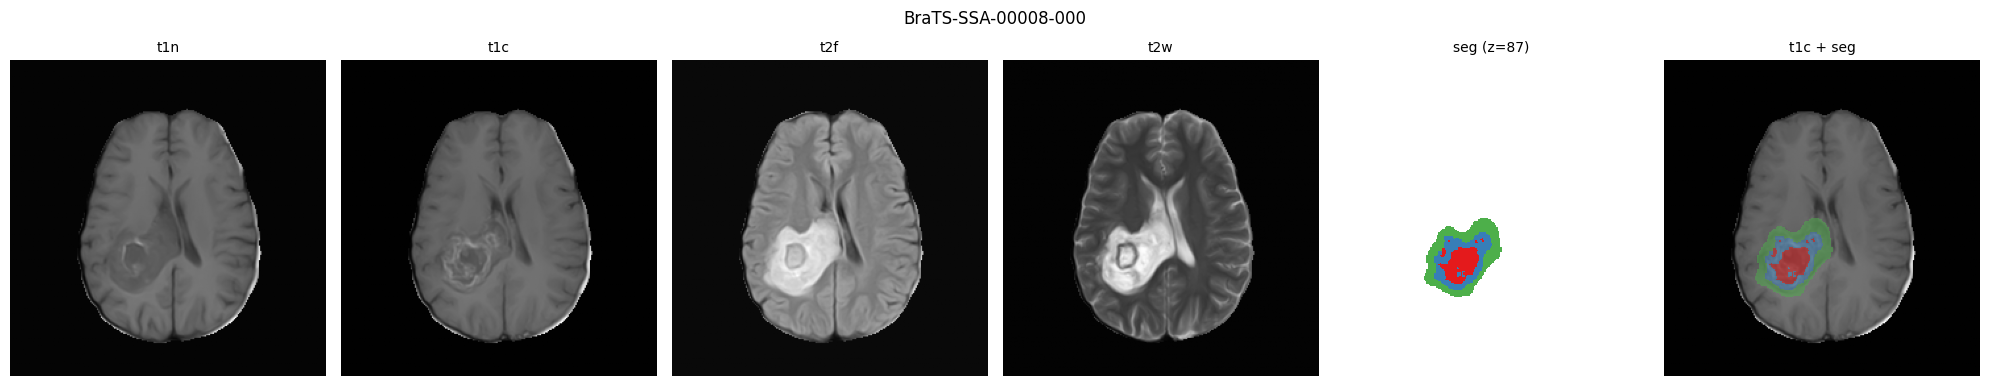

In [48]:
visualize_case(image_t1n, image_t1c, image_t2f, image_t2w, mask,
               title=os.path.basename(case))
plt.show()

The standalone mask lets me check the colors without transparency. I compare it with the classes counted in the slice.


### Inspect all three planes

With the RAS orientation checked above, axes 0, 1, and 2 correspond to sagittal, coronal, and axial views, respectively.


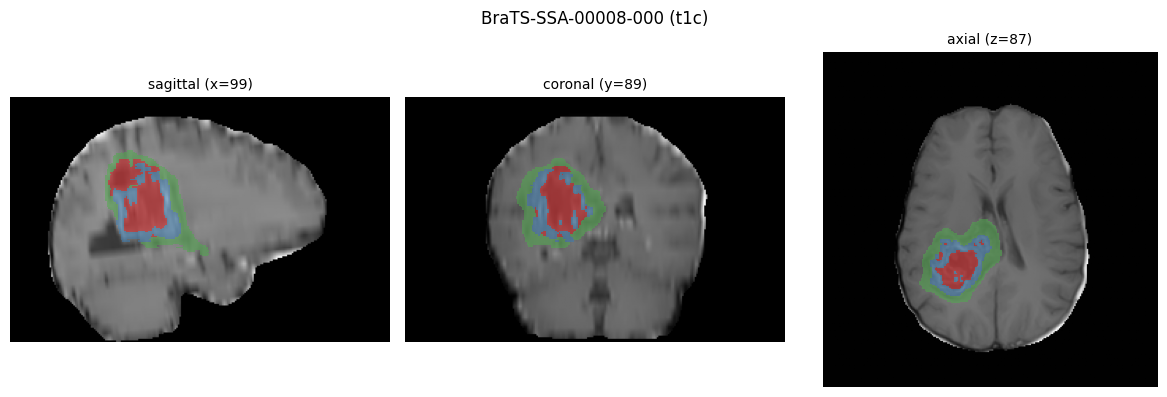

In [49]:
visualize_planes(image_t1c, mask, title="{} (t1c)".format(os.path.basename(case)))
plt.show()

### Isolate each tumor region


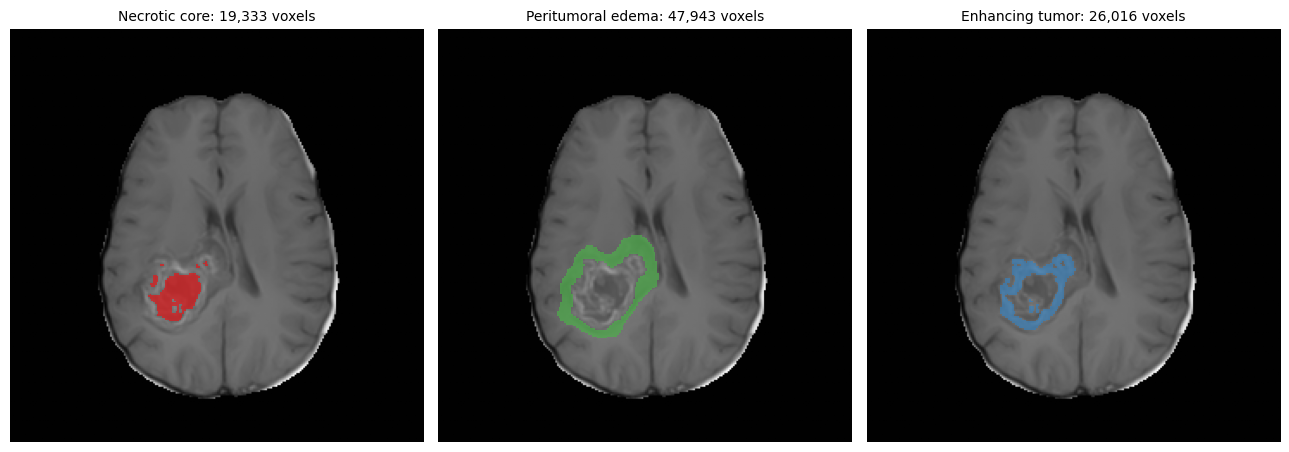

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, label in zip(axes, (1, 2, 3)):
    _overlay(ax, image_t1c[:, :, z], np.where(mask[:, :, z] == label, label, 0), alpha=0.7)
    ax.set_title("{}: {:,} voxels".format(LABEL_NAMES[label], int((mask == label).sum())),
                 fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

### Browse several slices


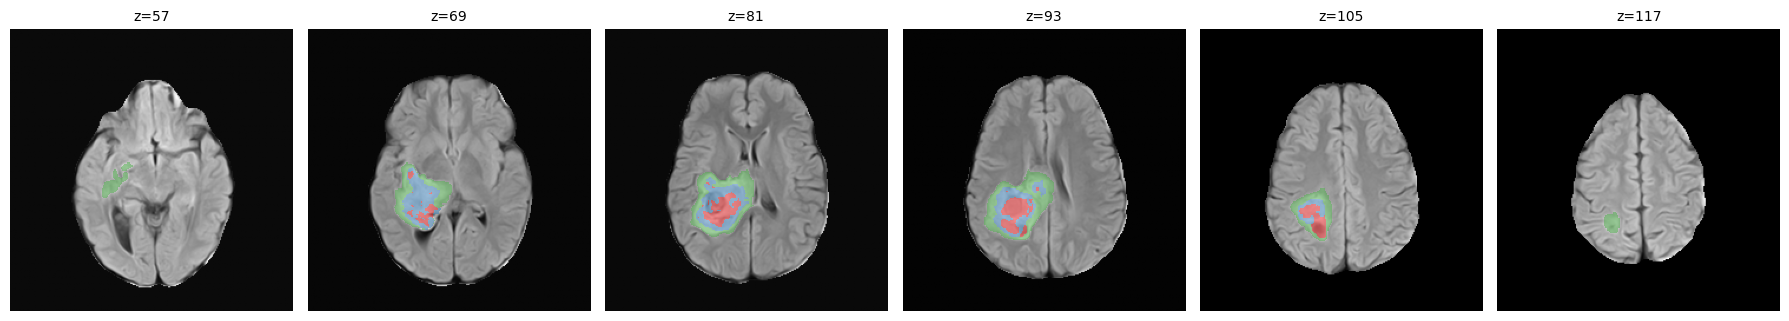

In [51]:
slice_ids = np.linspace(max(z - 30, 0), min(z + 30, mask.shape[2] - 1), 6).astype(int)

fig, axes = plt.subplots(1, len(slice_ids), figsize=(18, 3.5))
for ax, index in zip(axes, slice_ids):
    _overlay(ax, image_t2f[:, :, index], mask[:, :, index])
    ax.set_title("z={}".format(index), fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Understand the labels

| Label | Region |
|---|---|
| 0 | Background and tissue outside the annotated tumor regions |
| 1 | Necrotic tumor core |
| 2 | Peritumoral edema |
| 3 | Enhancing tumor |

These numbers represent categories, so I do not normalize the mask like an intensity image.


In [52]:
labels, counts = np.unique(mask, return_counts=True)

pd.DataFrame({
    "label": labels.astype(int),
    "voxels": counts,
    "percent_of_volume": (100 * counts / counts.sum()).round(3),
})

,label,voxels,percent_of_volume
0,0,8834708,98.955
1,1,19333,0.217
2,2,47943,0.537
3,3,26016,0.291


The proportion of label 0 shows the class imbalance. This motivates using Dice to monitor segmentation performance later.


### Check the label numbering

Some older BraTS releases use label 4 for enhancing tumor. I check the values in this copy before deciding whether a `4 -> 3` remapping is needed.


In [53]:
label_presence = {}
for case_dir in case_dirs:
    try:
        seg = np.asanyarray(nib.load(case_file(case_dir, "seg")).dataobj)
    except FileNotFoundError:
        continue
    for label in np.unique(seg):
        label_presence[int(label)] = label_presence.get(int(label), 0) + 1

print("Label   Cases containing it")
for label in sorted(label_presence):
    print("{:>5}   {}".format(label, label_presence[label]))

print()
print("Label 4 found anywhere:", 4 in label_presence)

Label   Cases containing it
    0   95
    1   88
    2   95
    3   95

Label 4 found anywhere: False


If the masks contain only labels 0 through 3, no remapping is needed. `uint8` is sufficient to store these categories and reduces memory use.


In [54]:
mask_img = nib.load(case_file(case, "seg"))

print("Data type on disk:        ", mask_img.get_data_dtype())
print("get_fdata data type:      ", mask_img.get_fdata().dtype)
print("dataobj data type:        ", np.asanyarray(mask_img.dataobj).dtype)
print()
print("Memory as float64: {:>7.1f} MB".format(mask_img.get_fdata().nbytes / 1e6))
print("Memory as uint8:   {:>7.1f} MB".format(
    np.asanyarray(mask_img.dataobj).astype(np.uint8).nbytes / 1e6))

Data type on disk:         float32
get_fdata data type:       float64
dataobj data type:         float32

Memory as float64:    71.4 MB
Memory as uint8:       8.9 MB


## 7. Preprocess one case

I test each operation on one patient before applying it to all cases.

### 7.1 Normalize intensities

The function below uses `MinMaxScaler` to bring values into the range 0 to 1. The volume is reshaped into a 2D table, then restored to its original shape.


In [55]:
def scale_volume(volume):
    scaler = MinMaxScaler()
    flat = volume.reshape(-1, volume.shape[-1])
    return scaler.fit_transform(flat).reshape(volume.shape)

In [56]:
raw = volumes["t1c"]
scaled = scale_volume(raw)

print("Before scaling: min {:>10.2f}  max {:>10.2f}".format(raw.min(), raw.max()))
print("After scaling:  min {:>10.2f}  max {:>10.2f}".format(scaled.min(), scaled.max()))

Before scaling: min    -312.00  max   12939.00
After scaling:  min       0.00  max       1.00


With `reshape(-1, volume.shape[-1])`, each slice becomes a column, so normalization is applied **slice by slice**. This preserves the original code's behavior but does not preserve intensity differences between slices.

### 7.2 Stack the four sequences

I stack the sequences along the last axis, giving each voxel four input channels.


In [57]:
channels = [scale_volume(volumes[name]) for name in MODALITIES]
image = np.stack(channels, axis=3)

print("One sequence:   ", channels[0].shape)
print("Stacked volume: ", image.shape)

One sequence:    (240, 240, 155)
Stacked volume:  (240, 240, 155, 4)


### 7.3 Crop the volumes

I crop from `240 x 240 x 155` to `128 x 128 x 128` using `56:184`, `56:184`, and `13:141`. This saves memory but can remove useful tissue, so I inspect the cropped images and masks. A size of 128 is compatible with the successive downsampling steps in the U-Net.


In [58]:
image_cropped = image[CROP]
mask_cropped = np.asanyarray(nib.load(case_file(case, "seg")).dataobj).astype(np.uint8)[CROP]

print("Image before: {}  {:>7.1f} MB".format(image.shape, image.nbytes / 1e6))
print("Image after:  {}  {:>7.1f} MB".format(image_cropped.shape, image_cropped.nbytes / 1e6))
print("Voxels kept:  {:.1f}%".format(100 * image_cropped.size / image.size))
print()
print("Mask before:  {}".format(mask.shape))
print("Mask after:   {}".format(mask_cropped.shape))

Image before: (240, 240, 155, 4)    285.7 MB
Image after:  (128, 128, 128, 4)     67.1 MB
Voxels kept:  23.5%

Mask before:  (240, 240, 155)
Mask after:   (128, 128, 128)


I convert the normalized images to `float32`, halving memory use compared with `float64`.


In [59]:
image_cropped = image_cropped.astype(np.float32)
print("As float32:   {}  {:>7.1f} MB".format(image_cropped.shape, image_cropped.nbytes / 1e6))

As float32:   (128, 128, 128, 4)     33.6 MB


### 7.4 One-hot encode the mask

Each class becomes a binary channel. Indexing an identity matrix performs this encoding directly in NumPy using `uint8`. The PyTorch notebook converts these channels back to class indices for the loss.


In [60]:
def one_hot(mask_array, num_classes=NUM_CLASSES):
    return np.eye(num_classes, dtype=np.uint8)[mask_array]

In [61]:
mask_onehot = one_hot(mask_cropped)

print("Labels shape:  {}  {:>7.1f} MB".format(mask_cropped.shape, mask_cropped.nbytes / 1e6))
print("One-hot shape: {}  {:>7.1f} MB".format(mask_onehot.shape, mask_onehot.nbytes / 1e6))
print()
print("Check: every voxel sums to 1 across the four channels:",
      bool(np.all(mask_onehot.sum(axis=-1) == 1)))

Labels shape:  (128, 128, 128)      2.1 MB
One-hot shape: (128, 128, 128, 4)      8.4 MB

Check: every voxel sums to 1 across the four channels: True


### 7.5 Check the result

I visually check that cropping and normalization have preserved the correspondence between MRI scans and annotations.


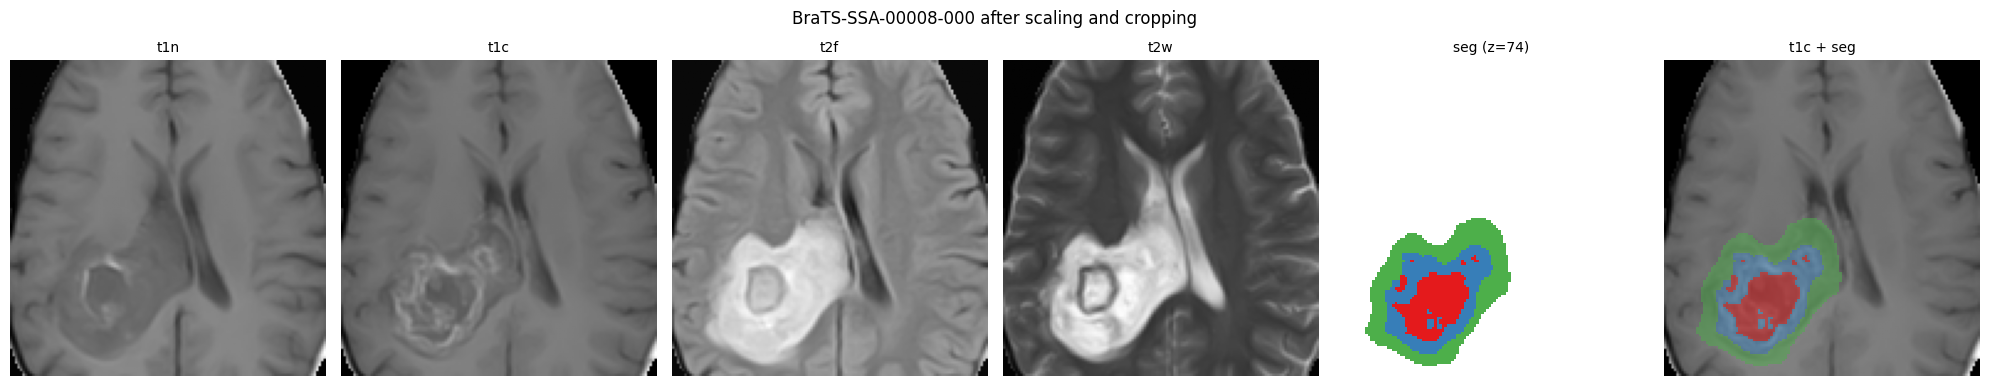

In [62]:
visualize_case(image_cropped[:, :, :, 0], image_cropped[:, :, :, 1],
               image_cropped[:, :, :, 2], image_cropped[:, :, :, 3], mask_cropped,
               title="{} after scaling and cropping".format(os.path.basename(case)))
plt.show()

## 8. Filter cases with little tumor

The code keeps cases where at least 1% of the cropped volume is annotated as tumor. I retain this threshold from the tutorial. It changes patient selection and needs to be considered when interpreting the results.


In [63]:
def tumor_fraction(mask_array):
    return float((mask_array > 0).sum() / mask_array.size)


print("Tumor fraction for this case: {:.4f}".format(tumor_fraction(mask_cropped)))

Tumor fraction for this case: 0.0445


## 9. Combine the preprocessing steps

I collect these steps in `preprocess_case` so that each patient is processed consistently.


In [64]:
def preprocess_case(case_dir):
    channels = [scale_volume(nib.load(case_file(case_dir, name)).get_fdata())
                for name in MODALITIES]
    image = np.stack(channels, axis=3)[CROP].astype(np.float32)

    labels = np.asanyarray(nib.load(case_file(case_dir, "seg")).dataobj).astype(np.uint8)
    labels = labels[CROP]

    return image, labels

In [65]:
test_image, test_mask = preprocess_case(case_dirs[0])

print("Image:", test_image.shape, test_image.dtype)
print("Mask: ", test_mask.shape, test_mask.dtype)
print("Tumor fraction: {:.4f}".format(tumor_fraction(test_mask)))

Image: (128, 128, 128, 4) float32
Mask:  (128, 128, 128) uint8
Tumor fraction: 0.1034


## 10. Process all cases

I save the images and masks as `.npy` files. A summary table records which cases were kept or skipped. I allow a few gigabytes of free disk space before running this step.


In [66]:
def process_dataset(case_dirs, output_root, min_tumor_fraction=0.01, verbose=True):
    image_dir = os.path.join(output_root, "images")
    mask_dir = os.path.join(output_root, "masks")
    os.makedirs(image_dir, exist_ok=True)
    os.makedirs(mask_dir, exist_ok=True)

    summary = []
    for index, case_dir in enumerate(case_dirs):
        name = os.path.basename(case_dir)

        try:
            image, labels = preprocess_case(case_dir)
        except FileNotFoundError as error:
            summary.append({"case": name, "status": "missing file", "tumor_fraction": np.nan})
            if verbose:
                print("[skip] {}: {}".format(name, error))
            continue

        fraction = tumor_fraction(labels)
        if fraction < min_tumor_fraction:
            summary.append({"case": name, "status": "below threshold", "tumor_fraction": fraction})
            if verbose:
                print("[skip] {}: tumor fraction {:.4f}".format(name, fraction))
            continue

        np.save(os.path.join(image_dir, "image_{}.npy".format(index)), image)
        np.save(os.path.join(mask_dir, "mask_{}.npy".format(index)), one_hot(labels))

        summary.append({"case": name, "status": "saved", "tumor_fraction": fraction})
        if verbose:
            print("[save] {}: tumor fraction {:.4f}".format(name, fraction))

    return pd.DataFrame(summary)

In [67]:
summary = process_dataset(case_dirs, OUTPUT_ROOT)
summary["status"].value_counts()

[save] BraTS-SSA-00002-000: tumor fraction 0.1034
[save] BraTS-SSA-00007-000: tumor fraction 0.1393
[save] BraTS-SSA-00008-000: tumor fraction 0.0445
[save] BraTS-SSA-00010-000: tumor fraction 0.0713
[save] BraTS-SSA-00011-000: tumor fraction 0.0984
[save] BraTS-SSA-00012-000: tumor fraction 0.0715
[save] BraTS-SSA-00014-000: tumor fraction 0.0573
[save] BraTS-SSA-00015-000: tumor fraction 0.1825
[save] BraTS-SSA-00025-000: tumor fraction 0.1140
[save] BraTS-SSA-00026-000: tumor fraction 0.0495
[save] BraTS-SSA-00028-000: tumor fraction 0.0805
[save] BraTS-SSA-00037-000: tumor fraction 0.0152
[save] BraTS-SSA-00041-000: tumor fraction 0.0297
[save] BraTS-SSA-00044-000: tumor fraction 0.0720
[save] BraTS-SSA-00046-000: tumor fraction 0.0307
[skip] BraTS-SSA-00047-000: tumor fraction 0.0061
[save] BraTS-SSA-00049-000: tumor fraction 0.0493
[save] BraTS-SSA-00050-000: tumor fraction 0.0516
[save] BraTS-SSA-00051-000: tumor fraction 0.0425
[save] BraTS-SSA-00055-000: tumor fraction 0.0773


status
saved              89
below threshold     6
Name: count, dtype: int64

In [68]:
summary.head(15)

,case,status,tumor_fraction
0,BraTS-SSA-00002-000,saved,0.103382
1,BraTS-SSA-00007-000,saved,0.139339
2,BraTS-SSA-00008-000,saved,0.044485
3,BraTS-SSA-00010-000,saved,0.071258
4,BraTS-SSA-00011-000,saved,0.098372
5,BraTS-SSA-00012-000,saved,0.071472
6,BraTS-SSA-00014-000,saved,0.057293
7,BraTS-SSA-00015-000,saved,0.182548
8,BraTS-SSA-00025-000,saved,0.113951
9,BraTS-SSA-00026-000,saved,0.049529


## 11. Compare storage use

I measure the sizes of the raw and preprocessed folders.


In [69]:
def folder_size_mb(path):
    total = 0
    for entry in glob.glob(os.path.join(path, "**", "*"), recursive=True):
        if os.path.isfile(entry):
            total += os.path.getsize(entry)
    return total / 1e6


raw_mb = folder_size_mb(DATA_ROOT)
processed_mb = folder_size_mb(OUTPUT_ROOT)
kept = int((summary["status"] == "saved").sum())

print("Raw NIfTI on disk:      {:>9.1f} MB across {} cases".format(raw_mb, len(case_dirs)))
print("Processed NumPy arrays: {:>9.1f} MB across {} cases".format(processed_mb, kept))
print()
if kept:
    print("Per kept case: {:.1f} MB".format(processed_mb / kept))

Raw NIfTI on disk:         1123.1 MB across 95 cases
Processed NumPy arrays:    3733.0 MB across 89 cases

Per kept case: 41.9 MB


The `.npy` files are uncompressed here, and one-hot encoding adds mask channels. The folder can therefore grow despite cropping. In return, the arrays are ready to load during training.


In [70]:
saved_images = sorted(glob.glob(os.path.join(OUTPUT_ROOT, "images", "*.npy")))
saved_masks = sorted(glob.glob(os.path.join(OUTPUT_ROOT, "masks", "*.npy")))

print("Saved image files:", len(saved_images))
print("Saved mask files: ", len(saved_masks))

checked_image = np.load(saved_images[0])
checked_mask = np.load(saved_masks[0])

print()
print("Image: {} {} range [{:.2f}, {:.2f}]".format(
    checked_image.shape, checked_image.dtype, checked_image.min(), checked_image.max()))
print("Mask:  {} {} classes present {}".format(
    checked_mask.shape, checked_mask.dtype, np.unique(np.argmax(checked_mask, axis=-1))))

Saved image files: 89
Saved mask files:  89

Image: (128, 128, 128, 4) float32 range [0.00, 1.00]
Mask:  (128, 128, 128, 4) uint8 classes present [0 1 2 3]


## 12. Split the patients

I split the cases into **75% training, 15% validation, and 10% test**, using a fixed seed. Images must stay paired with their masks. Validation monitors learning; the test set is reserved for final evaluation.


In [71]:
import splitfolders
import shutil

splitfolders.ratio(
    OUTPUT_ROOT + "/",
    output="glioma_split_data/",
    seed=42,
    ratio=(0.75, 0.15, 0.10),
    group_prefix=None,
)

DRIVE_SAVE_DIR = "/content/drive/MyDrive/BT_Segmentation/glioma_split_data"

if os.path.exists(DRIVE_SAVE_DIR):
    shutil.rmtree(DRIVE_SAVE_DIR)
shutil.copytree("glioma_split_data", DRIVE_SAVE_DIR)

print("Split data saved to Google Drive:")
print(DRIVE_SAVE_DIR)

Copying files: 178 files [00:41,  4.25 files/s]


Split data saved to Google Drive:
/content/drive/MyDrive/BT_Segmentation/glioma_split_data


In [72]:
for split in ["train", "val", "test"]:
    images = glob.glob(os.path.join("glioma_split_data", split, "images", "*.npy"))
    masks = glob.glob(os.path.join("glioma_split_data", split, "masks", "*.npy"))
    print("{:<6} images: {:>3}   masks: {:>3}".format(split, len(images), len(masks)))

train  images:  66   masks:  66
val    images:  13   masks:  13
test   images:  10   masks:  10


## Ready for training

I have inspected the scans, prepared the volumes, and created the three sets. Next is [02_unet3d_pytorch_brain_segmentation.ipynb](02_unet3d_pytorch_brain_segmentation.ipynb), which uses the `glioma_split_data` folder.
